<a href="https://colab.research.google.com/github/narayankarrahe/CUSTOMER-CHURN-PREDICTION-USING-MACHINE-LEARNING-DEEP-LEARNING/blob/main/Customer_Churn_Prediction_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
1. #Initial Data Cleaning and Transformation - Data Preprocessing
#Loadset
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Customer Churn.xlsx")
print("Original Shape:", df.shape)

df.head()

Original Shape: (3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [ ]:
2. #Check columns
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Columns:
['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']

Data Types:
Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object


In [ ]:
3. #Missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values:
Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Total Missing Values: 0


In [ ]:
4. #Duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 300


In [ ]:
5. #Remove duplicates
df = df.drop_duplicates()

In [ ]:
6. #Check
print("Duplicate Rows After Removal:", df.duplicated().sum())
print("New Shape:", df.shape)

Duplicate Rows After Removal: 0
New Shape: (2850, 14)


In [ ]:
7. #Remove redundant columns
df.drop('Age Group', axis=1, inplace=True)

In [ ]:
8. #Check constant columns
for column in df.columns:
    if df[column].nunique() == 1:
        print("Constant column:", column)

In [ ]:
9. #check values
print(df.head())

print("\nFinal Columns:")
print(df.columns.tolist())

   Call  Failure  Complains  Subscription  Length  Charge  Amount  \
0              8          0                    38               0   
1              0          0                    39               0   
2             10          0                    37               0   
3             10          0                    38               0   
4              3          0                    38               0   

   Seconds of Use  Frequency of use  Frequency of SMS  \
0            4370                71                 5   
1             318                 5                 7   
2            2453                60               359   
3            4198                66                 1   
4            2393                58                 2   

   Distinct Called Numbers  Tariff Plan  Status  Age  Customer Value  Churn  
0                       17            1       1   30         197.640      0  
1                        4            1       2   25          46.035      0  
2       

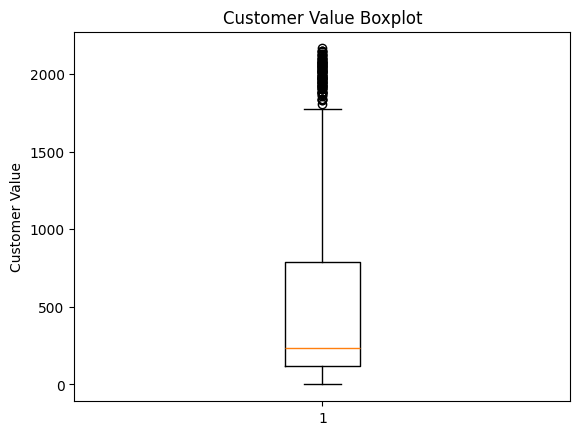

In [ ]:
10. #outlier check
import matplotlib.pyplot as plt

plt.boxplot(df['Customer Value'])

plt.ylabel("Customer Value")
plt.title("Customer Value Boxplot")

plt.show()

In [ ]:
11. #Sort tariff plan and status
df = df.sort_values(
    by=['Tariff Plan', 'Status'],
    ascending=[True, True]
)

In [ ]:
12. #Check
print(df[['Tariff Plan', 'Status']].head(5))

   Tariff Plan  Status
0            1       1
2            1       1
3            1       1
4            1       1
5            1       1


In [ ]:
13.  #Check the unique values
print(df['Tariff Plan'].unique())
print(df['Status'].unique())

[1 2]
[1 2]


In [ ]:
14. #Convert categorical values from 1,2 to binary 1,0
df['Tariff Plan'] = df['Tariff Plan'].replace({2: 0})
df['Status'] = df['Status'].replace({2: 0})

In [ ]:
15. # Check the unique values
print(df['Tariff Plan'].unique())
print(df['Status'].unique())

[1 0]
[1 0]


In [ ]:
16. #Check
print(df[['Tariff Plan','Status']].tail(5))

      Tariff Plan  Status
3038            0       1
3045            0       1
3095            0       1
3123            0       1
2972            0       0


In [ ]:
17. #Final check
print("Final Shape:", df.shape)

print("\nMissing Values:",
      df.isnull().sum().sum())

print("Duplicate Rows:",
      df.duplicated().sum())

Final Shape: (2850, 13)

Missing Values: 0
Duplicate Rows: 0


In [ ]:
18. #Save updated excel
output_file = "Updated_Customer_Churn_Prediction.xlsx"

df.to_excel(output_file, index=False)

print("Updated Customer Churn file created successfully!")

Updated Customer Churn file created successfully!


In [ ]:
19. #Download
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
20. #EDA
#load updated dataset
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/Updated_Customer_Churn_Prediction.xlsx")

print(df.shape)

df.head()

(2850, 13)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,1,1,30,197.640,0
1,10,0,37,0,2453,60,359,24,1,1,30,1536.520,0
2,10,0,38,0,4198,66,1,35,1,1,15,240.020,0
3,3,0,38,0,2393,58,2,33,1,1,15,145.805,0
4,11,0,38,1,3775,82,32,28,1,1,30,282.280,0


In [ ]:
21. #Descriptive statistics
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Tariff Plan,Status,Age,Customer Value,Churn
count,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000
mean,7.802456,0.080702,32.452982,0.974737,4534.243158,70.484912,73.789825,23.870526,0.919649,0.760000,31.077193,474.990367,0.156491
std,7.326172,0.272424,8.723075,1.550618,4199.712303,57.401512,112.062397,17.193929,0.271883,0.427158,8.861934,514.442198,0.363384
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,29.000000,0.000000,1458.750000,28.000000,7.000000,11.000000,1.000000,1.000000,25.000000,117.527500,0.000000
50%,6.000000,0.000000,35.000000,0.000000,3041.000000,54.500000,22.000000,21.000000,1.000000,1.000000,30.000000,232.520000,0.000000
75%,12.000000,0.000000,38.000000,2.000000,6500.000000,96.000000,88.000000,34.000000,1.000000,1.000000,30.000000,790.080000,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,1.000000,1.000000,55.000000,2165.280000,1.000000


In [ ]:
22. #Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2850 entries, 0 to 2849
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            2850 non-null   int64  
 1   Complains                2850 non-null   int64  
 2   Subscription  Length     2850 non-null   int64  
 3   Charge  Amount           2850 non-null   int64  
 4   Seconds of Use           2850 non-null   int64  
 5   Frequency of use         2850 non-null   int64  
 6   Frequency of SMS         2850 non-null   int64  
 7   Distinct Called Numbers  2850 non-null   int64  
 8   Tariff Plan              2850 non-null   int64  
 9   Status                   2850 non-null   int64  
 10  Age                      2850 non-null   int64  
 11  Customer Value           2850 non-null   float64
 12  Churn                    2850 non-null   int64  
dtypes: float64(1), int64(12)
memory usage: 289.6 KB


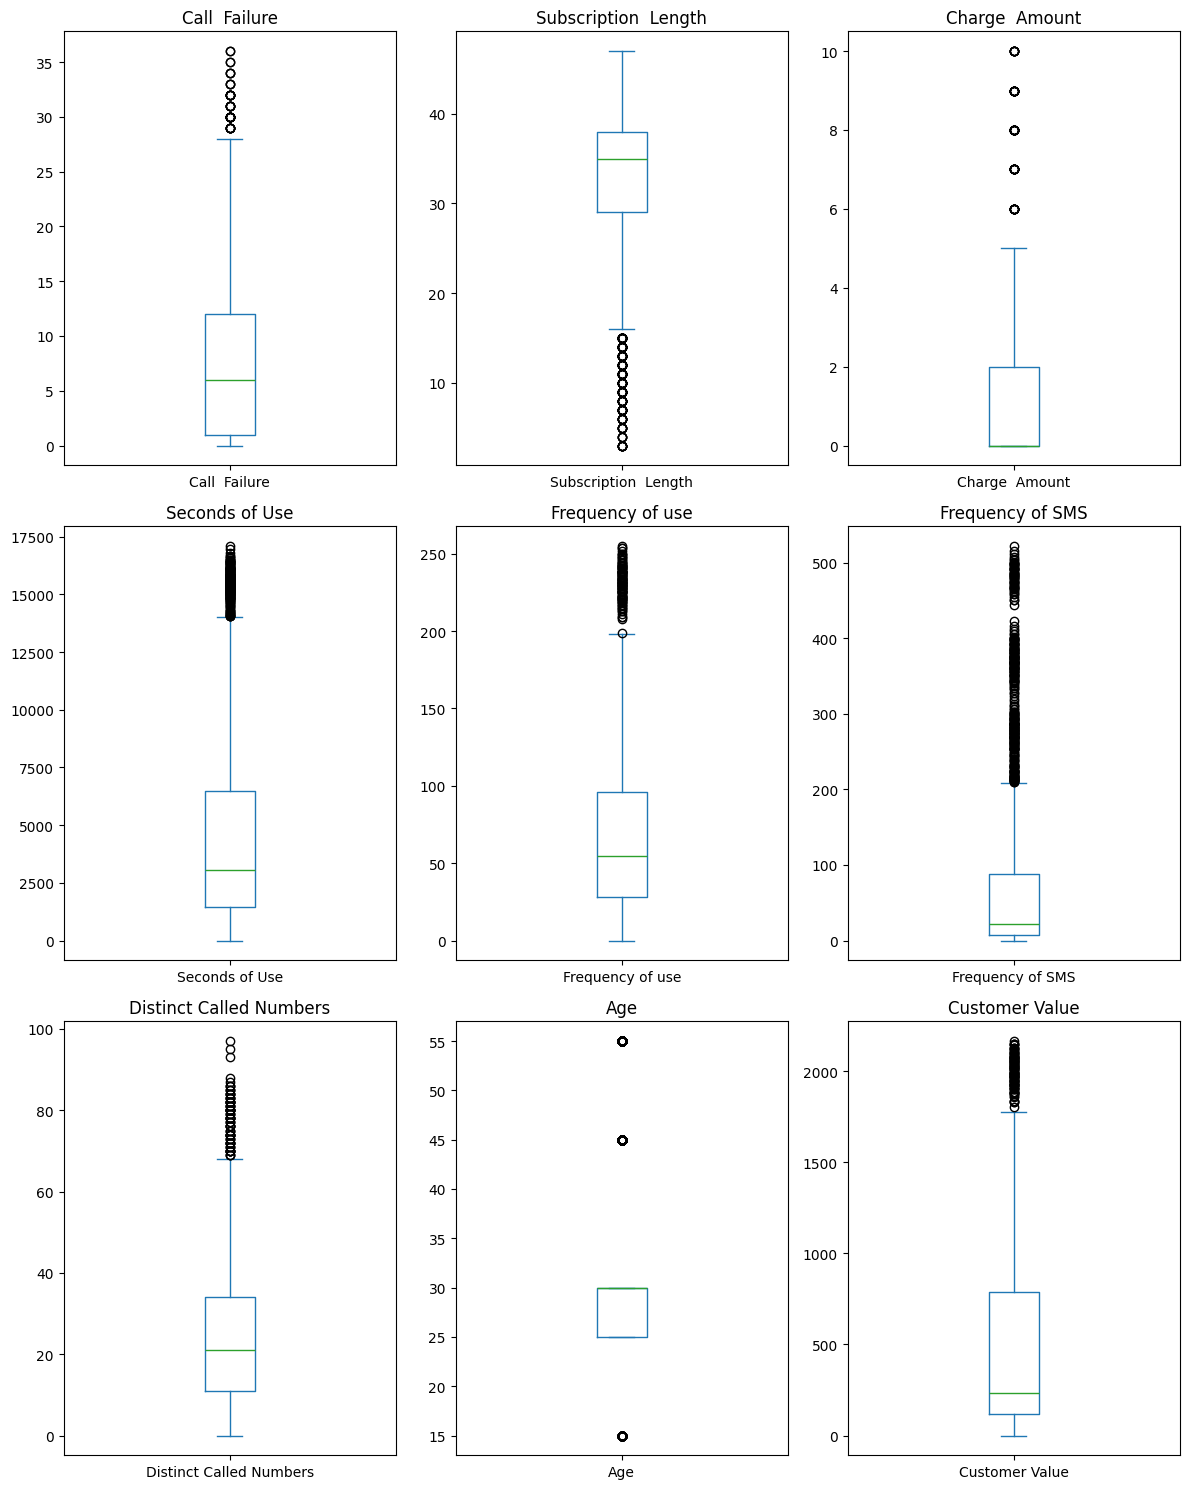

In [ ]:
23.# Box plots for all numerical columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() > 2].columns

fig, ax = plt.subplots(3, 3, figsize=(12, 15))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].plot(kind='box', ax=ax[i])
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

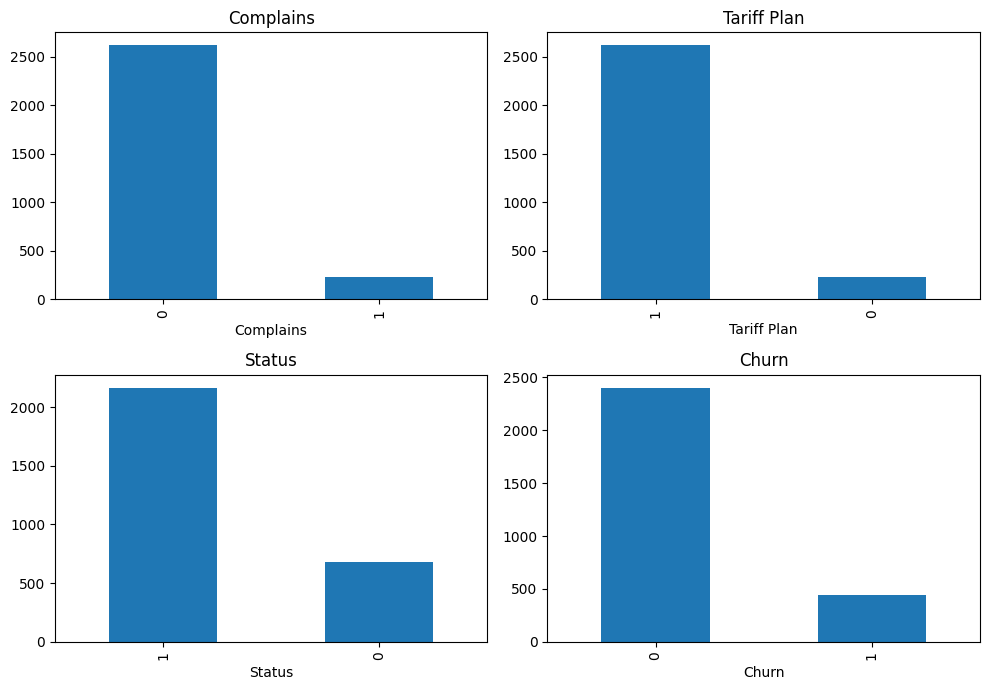

In [ ]:
24. # Bar charts for categorical columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() <= 2].columns

fig, ax = plt.subplots(2, 2, figsize=(10, 7))

for i, col in enumerate(columns):
    df[col].value_counts().plot(kind='bar', ax=ax.flat[i])
    ax.flat[i].set_title(col)
    ax.flat[i].grid(False)

plt.tight_layout()
plt.show()

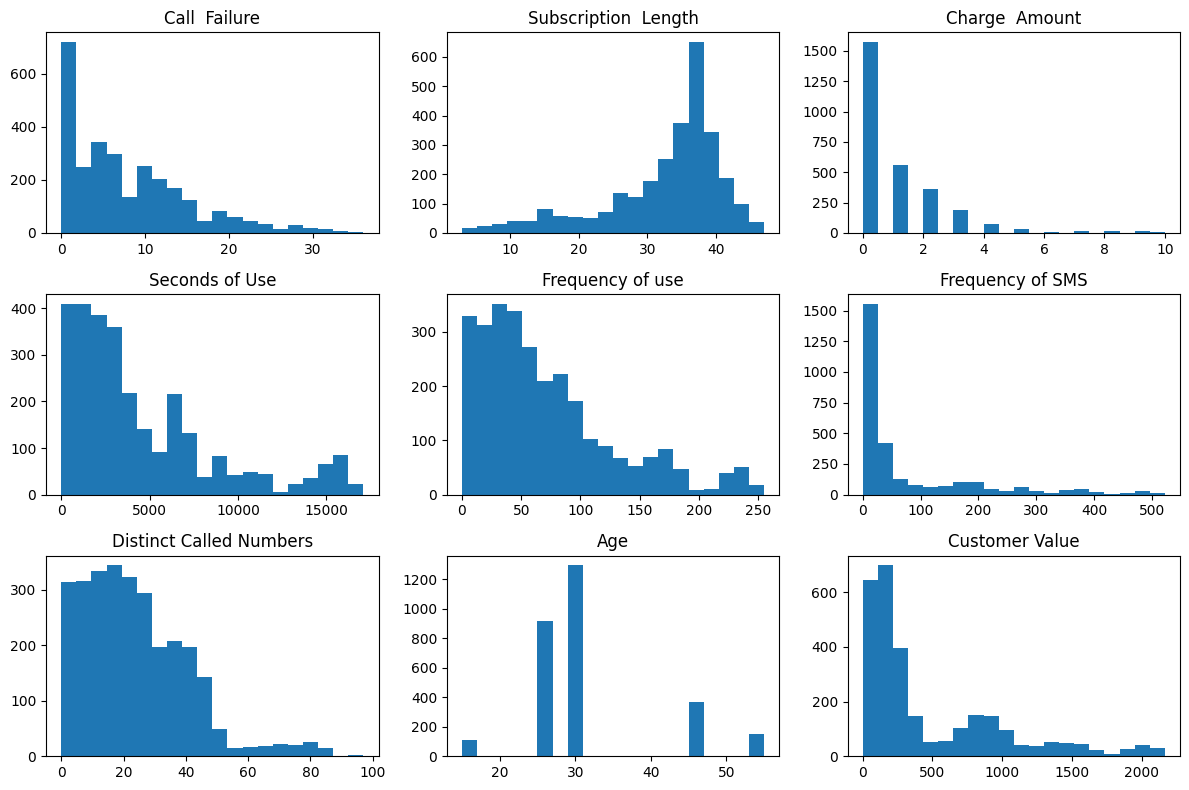

In [ ]:
25. # Histograms for numerical columns

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() > 2].columns

fig, ax = plt.subplots(3, 3, figsize=(12, 8))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].hist(bins=20, ax=ax[i])
    ax[i].set_title(col)
    ax[i].grid(False)

plt.tight_layout()
plt.show()

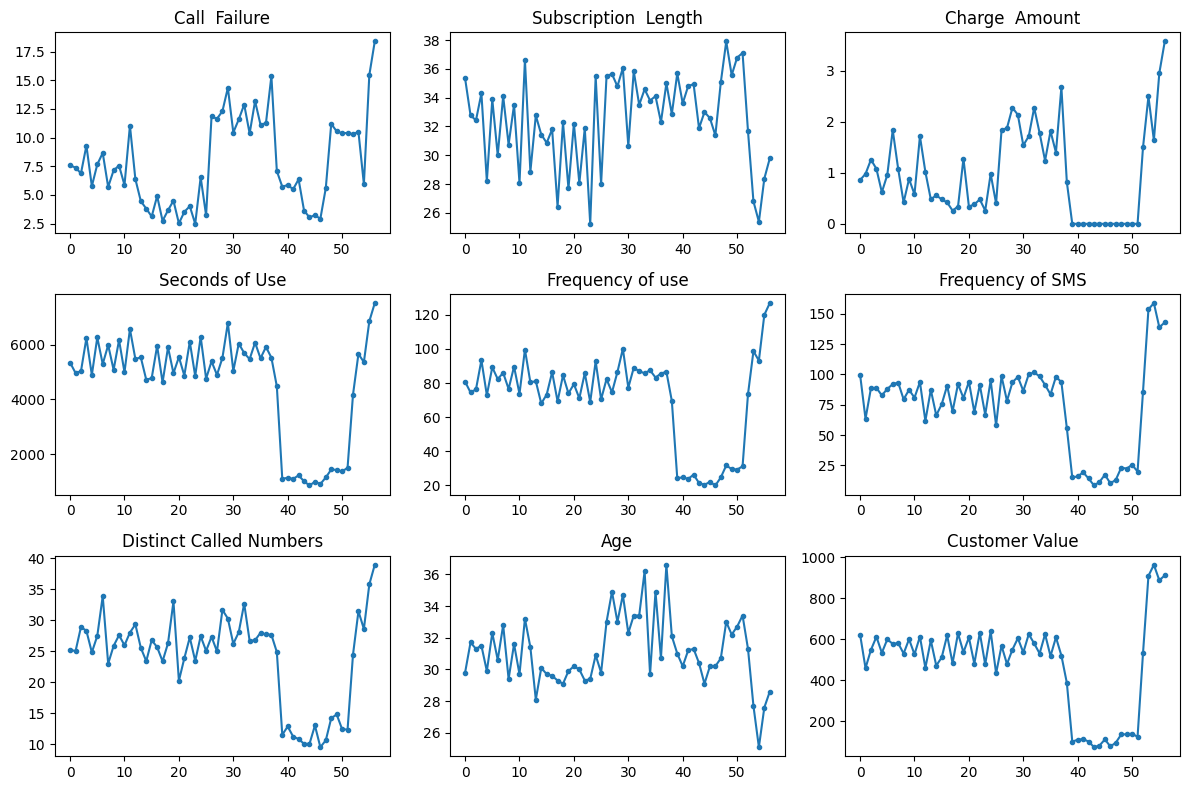

In [ ]:
26. #Line plots for numerical columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() > 2].columns

fig, ax = plt.subplots(3, 3, figsize=(12, 8))
ax = ax.flatten()

for i, col in enumerate(columns[:9]):
    df[col].groupby(df.index // 50).mean().plot(ax=ax[i], marker='o', markersize=3)
    ax[i].set_title(col)
    ax[i].grid(False)

plt.tight_layout()
plt.show()

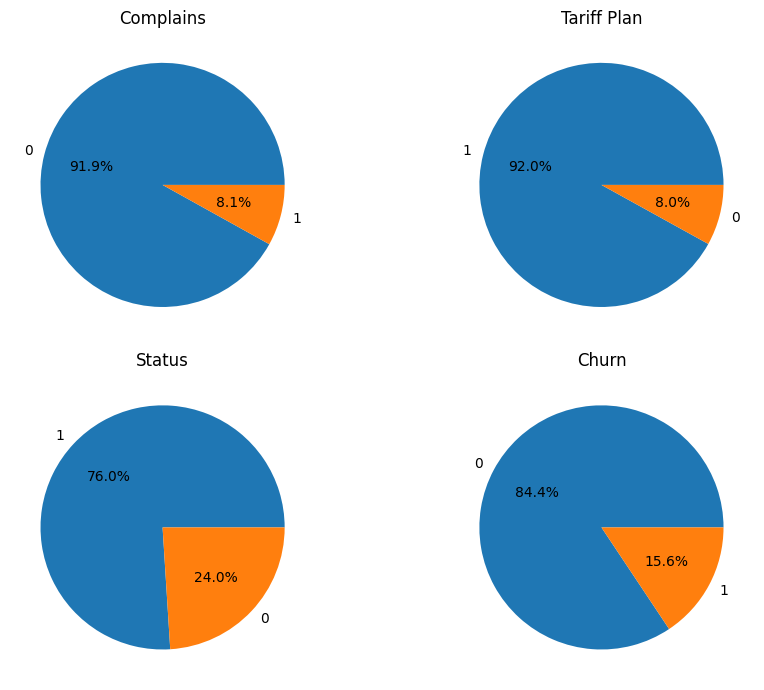

In [ ]:
27. #Pie Charts for categorical columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() <= 2].columns

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax = ax.flatten()

for i, col in enumerate(columns[:4]):
    df[col].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=ax[i])
    ax[i].set_title(col)
    ax[i].set_ylabel('')

plt.tight_layout()
plt.show()

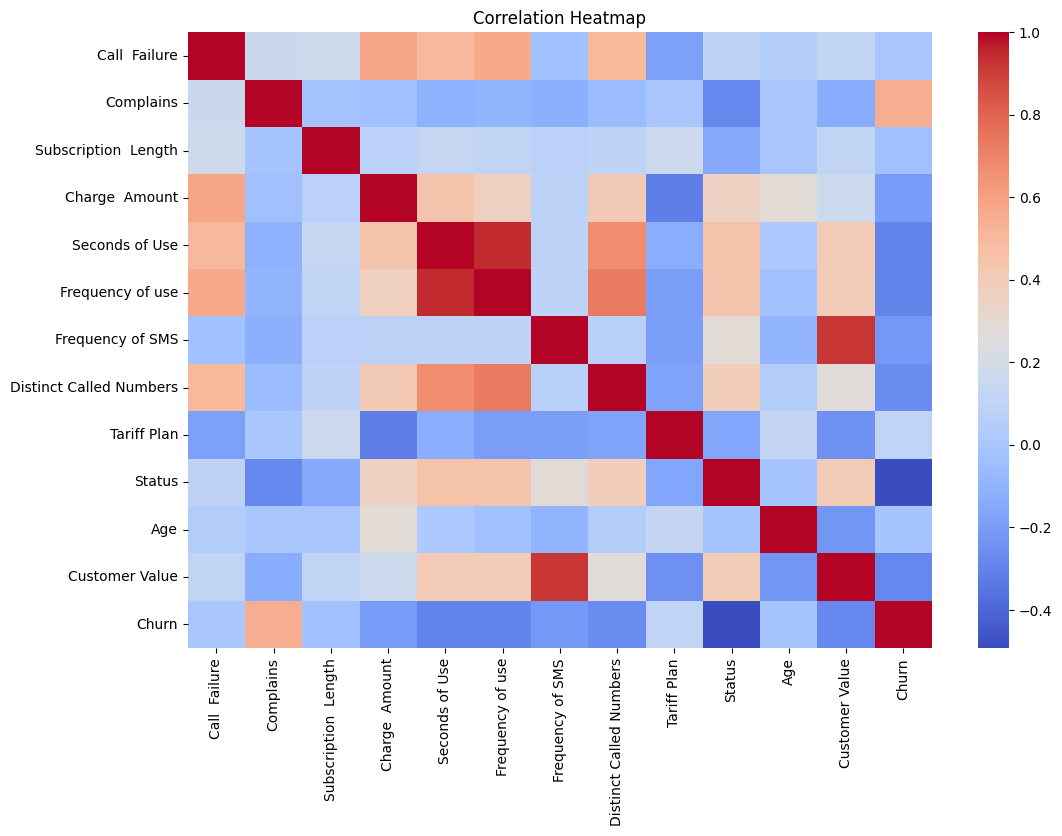

In [ ]:
28. #Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
29. #Correlation with churn
correlation = df.corr(numeric_only=True)['Churn']

print(correlation.sort_values(ascending=False))

Churn                      1.000000
Complains                  0.546055
Tariff Plan                0.106000
Call  Failure              0.003310
Age                       -0.011491
Subscription  Length      -0.037984
Charge  Amount            -0.201662
Frequency of SMS          -0.218894
Distinct Called Numbers   -0.270343
Customer Value            -0.287078
Seconds of Use            -0.295999
Frequency of use          -0.298608
Status                    -0.492867
Name: Churn, dtype: float64


In [ ]:
30. # Train-test split
from sklearn.model_selection import train_test_split

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# SMOTE
from imblearn.over_sampling import SMOTE

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Confusion matrix visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
31. # Separate input features and target variable
X = df.drop('Churn', axis=1)
y = df['Churn']

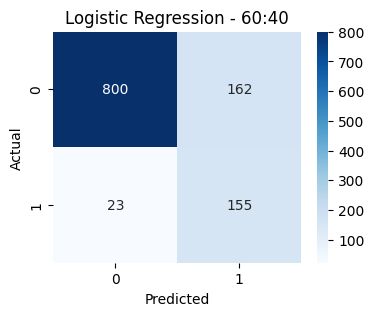

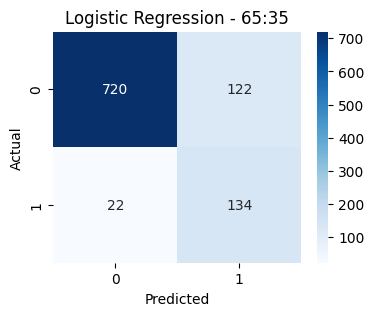

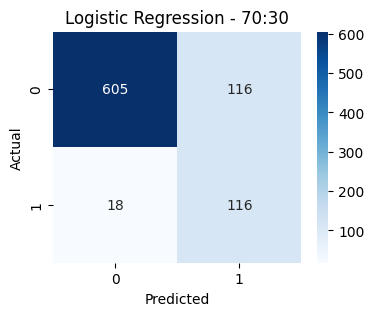

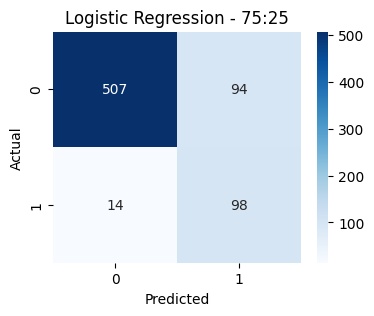

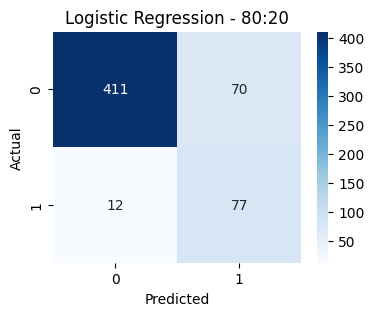

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.8377,0.4890,0.8708,0.6263,0.9343
1,65:35,0.8557,0.5234,0.8590,0.6505,0.9331
2,70:30,0.8433,0.5000,0.8657,0.6339,0.9353
3,75:25,0.8485,0.5104,0.8750,0.6447,0.9368
4,80:20,0.8561,0.5238,0.8652,0.6525,0.9421


In [ ]:
32. #MODEL BUILDING
# Logistic Regression - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Logistic Regression - {split_name}")
    plt.show()

logistic_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

logistic_results.iloc[:, 1:] = logistic_results.iloc[:, 1:].round(4)
display(logistic_results)

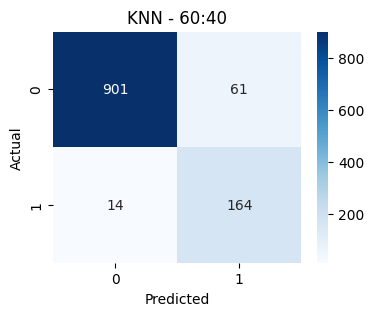

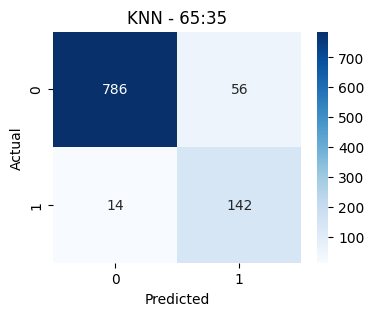

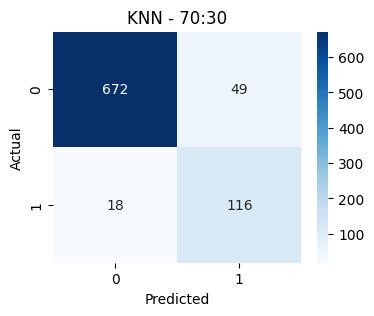

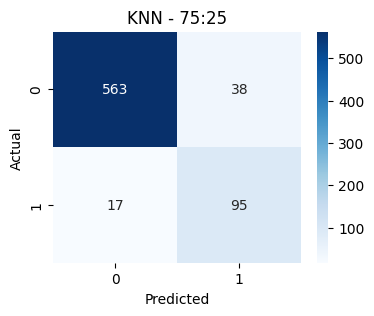

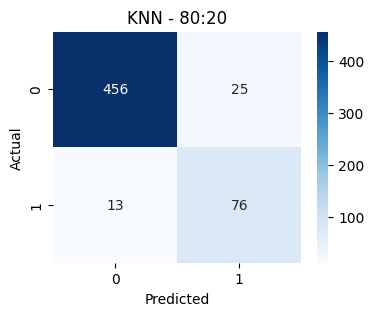

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.9342,0.7289,0.9213,0.8139,0.9574
1,65:35,0.9299,0.7172,0.9103,0.8023,0.9578
2,70:30,0.9216,0.7030,0.8657,0.7759,0.9579
3,75:25,0.9229,0.7143,0.8482,0.7755,0.9562
4,80:20,0.9333,0.7525,0.8539,0.8000,0.9525


In [ ]:
33. # KNN - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"KNN - {split_name}")
    plt.show()

knn_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

knn_results.iloc[:, 1:] = knn_results.iloc[:, 1:].round(4)
display(knn_results)

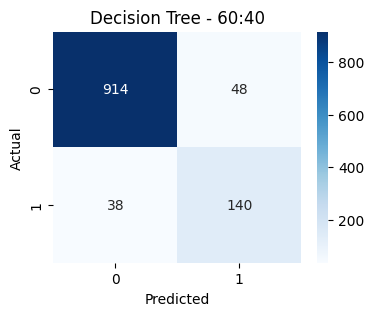

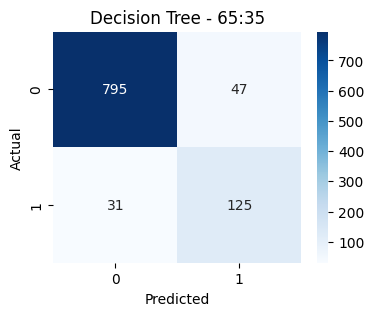

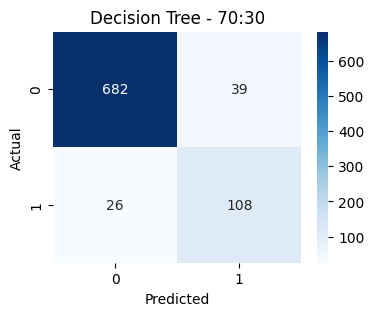

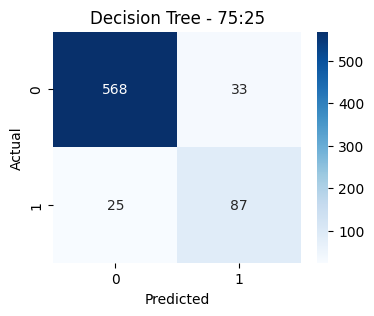

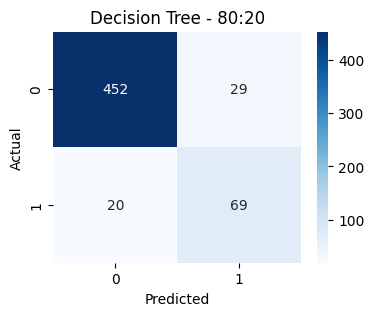

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.9246,0.7447,0.7865,0.7650,0.8682
1,65:35,0.9218,0.7267,0.8013,0.7622,0.8727
2,70:30,0.9240,0.7347,0.8060,0.7687,0.8757
3,75:25,0.9187,0.7250,0.7768,0.7500,0.8609
4,80:20,0.9140,0.7041,0.7753,0.7380,0.8573


In [ ]:
34. # Decision Tree - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Decision Tree - {split_name}")
    plt.show()

decision_tree_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

decision_tree_results.iloc[:, 1:] = decision_tree_results.iloc[:, 1:].round(4)
display(decision_tree_results)

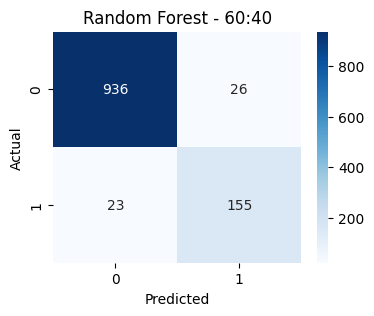

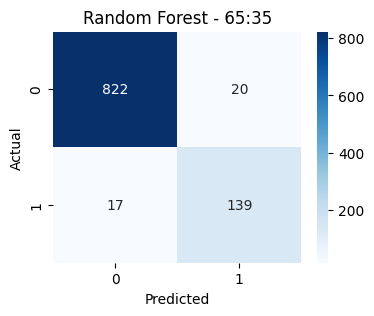

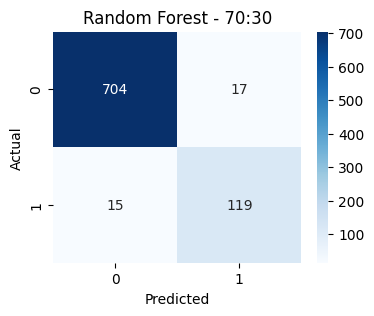

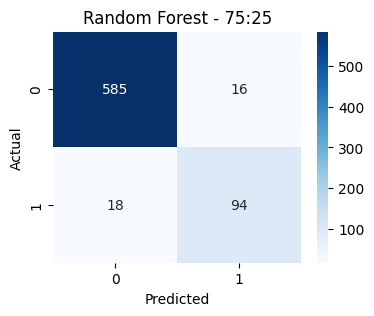

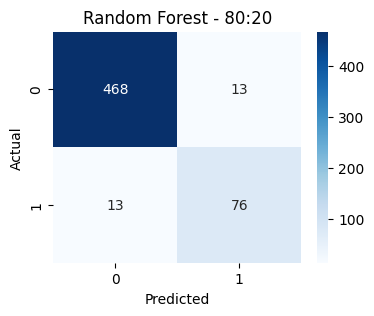

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.9570,0.8564,0.8708,0.8635,0.9741
1,65:35,0.9629,0.8742,0.8910,0.8825,0.9752
2,70:30,0.9626,0.8750,0.8881,0.8815,0.9745
3,75:25,0.9523,0.8545,0.8393,0.8468,0.9742
4,80:20,0.9544,0.8539,0.8539,0.8539,0.9717


In [ ]:
35. # Random Forest - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=36
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Random Forest - {split_name}")
    plt.show()

random_forest_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

random_forest_results.iloc[:, 1:] = random_forest_results.iloc[:, 1:].round(4)
display(random_forest_results)

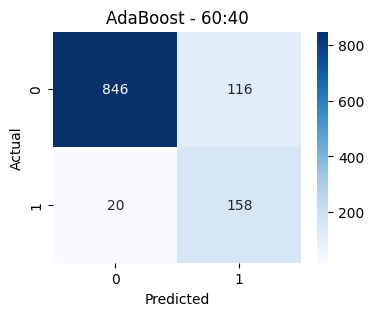

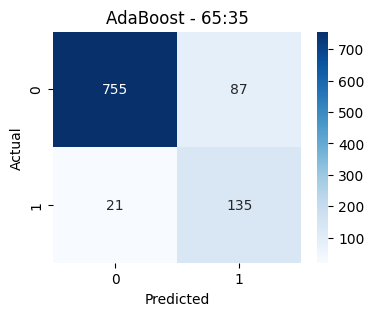

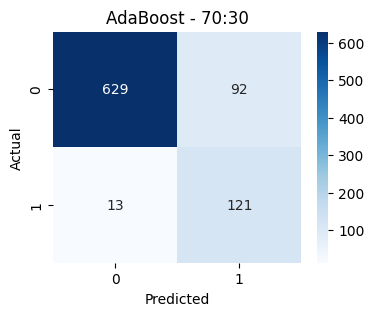

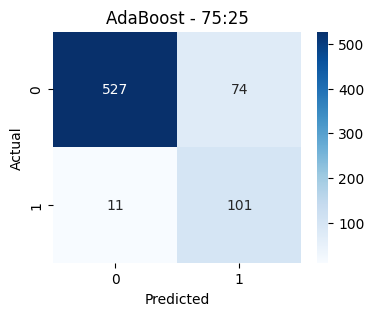

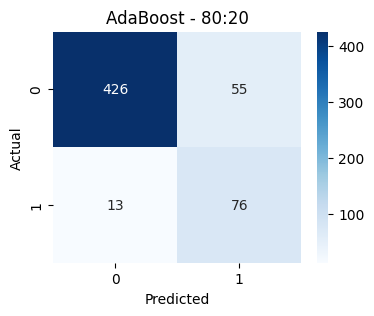

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.8807,0.5766,0.8876,0.6991,0.9537
1,65:35,0.8918,0.6081,0.8654,0.7143,0.9571
2,70:30,0.8772,0.5681,0.9030,0.6974,0.9581
3,75:25,0.8808,0.5771,0.9018,0.7038,0.9578
4,80:20,0.8807,0.5802,0.8539,0.6909,0.9575


In [ ]:
36. # AdaBoost - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = AdaBoostClassifier(random_state=36)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"AdaBoost - {split_name}")
    plt.show()

adaboost_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

adaboost_results.iloc[:, 1:] = adaboost_results.iloc[:, 1:].round(4)
display(adaboost_results)

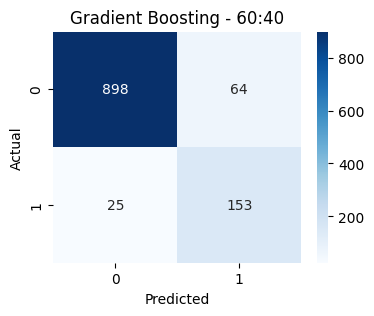

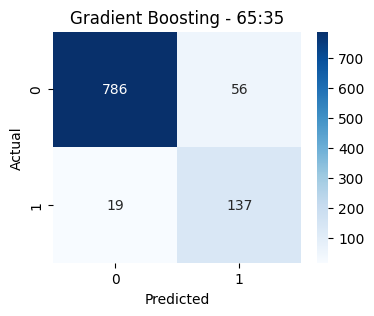

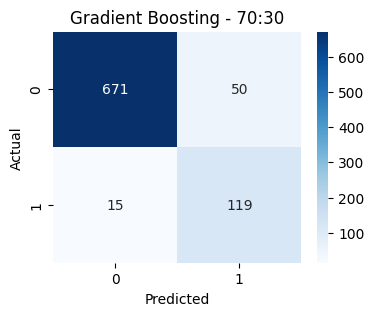

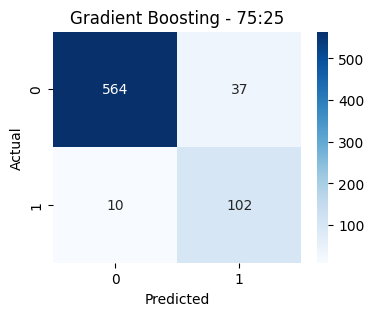

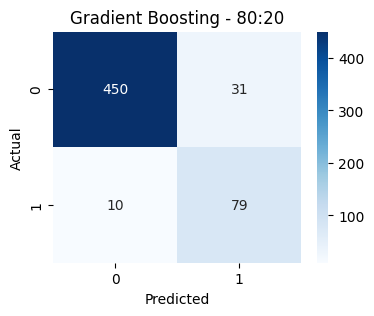

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.9219,0.7051,0.8596,0.7747,0.9676
1,65:35,0.9248,0.7098,0.8782,0.7851,0.9704
2,70:30,0.9240,0.7041,0.8881,0.7855,0.9689
3,75:25,0.9341,0.7338,0.9107,0.8127,0.9737
4,80:20,0.9281,0.7182,0.8876,0.7940,0.9725


In [ ]:
37. # Gradient Boosting - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=42)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = GradientBoostingClassifier(random_state=36)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Gradient Boosting - {split_name}")
    plt.show()

gradient_boosting_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

gradient_boosting_results.iloc[:, 1:] = gradient_boosting_results.iloc[:, 1:].round(4)
display(gradient_boosting_results)

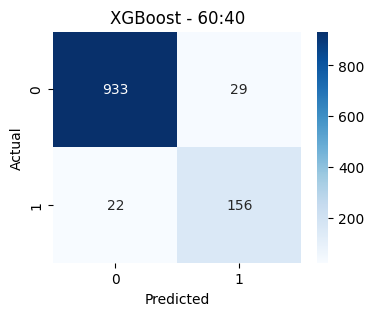

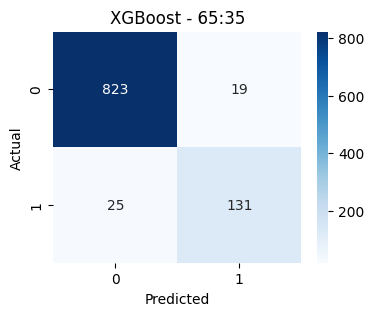

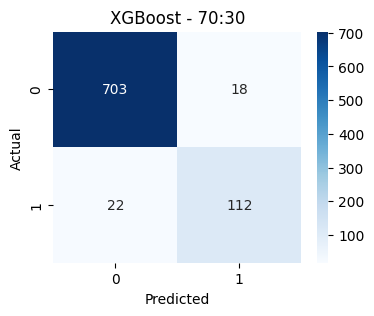

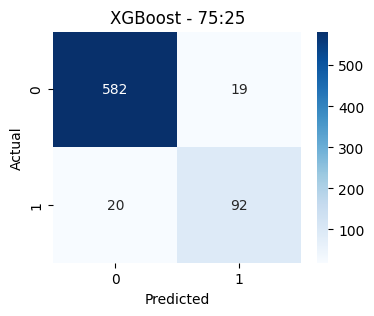

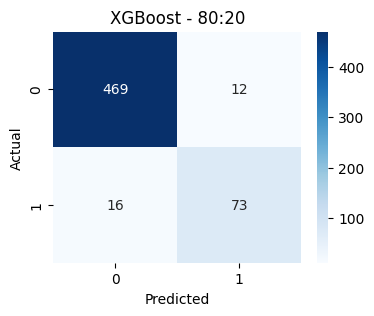

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.9553,0.8432,0.8764,0.8595,0.9817
1,65:35,0.9559,0.8733,0.8397,0.8562,0.9849
2,70:30,0.9532,0.8615,0.8358,0.8485,0.9796
3,75:25,0.9453,0.8288,0.8214,0.8251,0.9792
4,80:20,0.9509,0.8588,0.8202,0.8391,0.9807


In [ ]:
38. # XGBoost - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = XGBClassifier(
        n_estimators=100,
        random_state=36,
        eval_metric='logloss'
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"XGBoost - {split_name}")
    plt.show()

xgboost_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

xgboost_results.iloc[:, 1:] = xgboost_results.iloc[:, 1:].round(4)
display(xgboost_results)

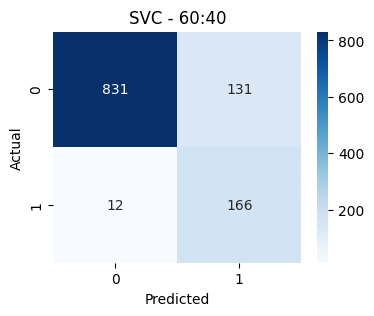

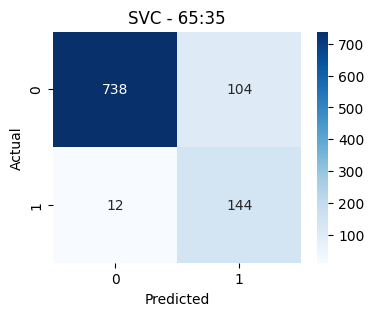

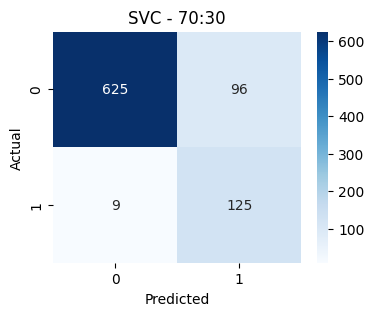

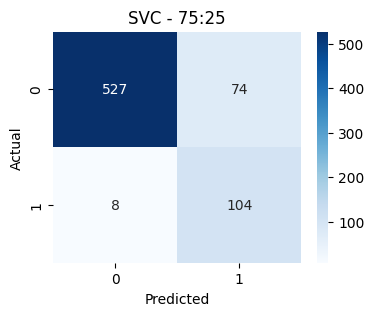

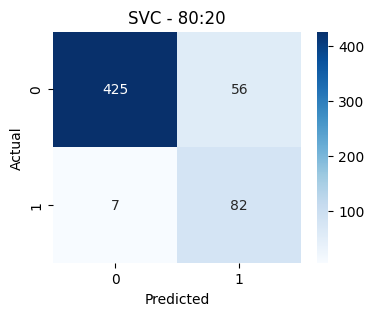

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.8746,0.5589,0.9326,0.6989,0.9613
1,65:35,0.8838,0.5806,0.9231,0.7129,0.9645
2,70:30,0.8772,0.5656,0.9328,0.7042,0.9639
3,75:25,0.8850,0.5843,0.9286,0.7172,0.9601
4,80:20,0.8895,0.5942,0.9213,0.7225,0.9564


In [ ]:
39. # SVC - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=42)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = SVC(probability=True, random_state=36)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"SVC - {split_name}")
    plt.show()

svc_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

svc_results.iloc[:, 1:] = svc_results.iloc[:, 1:].round(4)
display(svc_results)

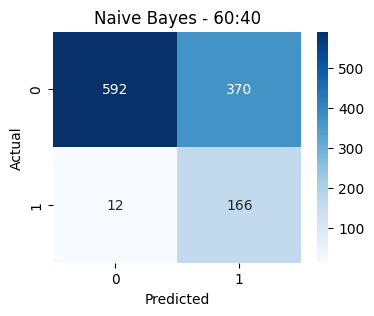

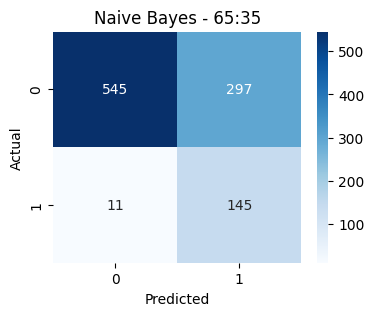

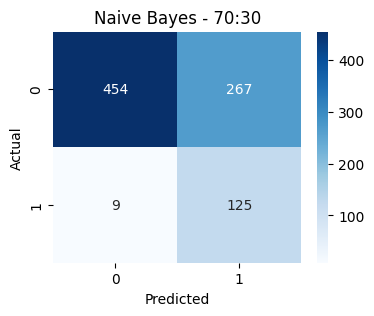

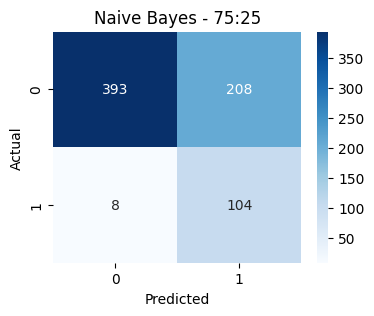

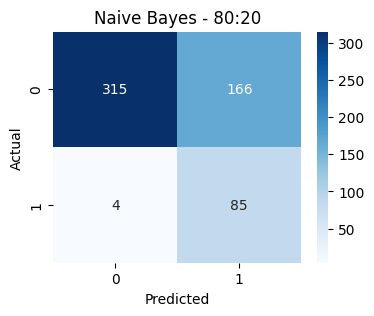

,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,60:40,0.6649,0.3097,0.9326,0.4650,0.9067
1,65:35,0.6914,0.3281,0.9295,0.4849,0.9071
2,70:30,0.6772,0.3189,0.9328,0.4753,0.9098
3,75:25,0.6971,0.3333,0.9286,0.4906,0.9140
4,80:20,0.7018,0.3386,0.9551,0.5000,0.9218


In [ ]:
40. # Naive Bayes - 5 Splits

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=36, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    smote = SMOTE(random_state=36)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    model = GaussianNB()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append([
        split_name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ])

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Naive Bayes - {split_name}")
    plt.show()

naive_bayes_results = pd.DataFrame(
    results,
    columns=["Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
)

naive_bayes_results.iloc[:, 1:] = naive_bayes_results.iloc[:, 1:].round(4)
display(naive_bayes_results)

In [ ]:
41. # Combine all model results
all_results = pd.concat([
    logistic_results.assign(Model="Logistic Regression"),
    knn_results.assign(Model="KNN"),
    decision_tree_results.assign(Model="Decision Tree"),
    random_forest_results.assign(Model="Random Forest"),
    adaboost_results.assign(Model="AdaBoost"),
    gradient_boosting_results.assign(Model="Gradient Boosting"),
    xgboost_results.assign(Model="XGBoost"),
    svc_results.assign(Model="SVC"),
    naive_bayes_results.assign(Model="Naive Bayes")
], ignore_index=True)

all_results = all_results[
    ["Model", "Split", "Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
]

display(all_results)

,Model,Split,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,Logistic Regression,60:40,0.8377,0.4890,0.8708,0.6263,0.9343
1,Logistic Regression,65:35,0.8557,0.5234,0.8590,0.6505,0.9331
2,Logistic Regression,70:30,0.8433,0.5000,0.8657,0.6339,0.9353
3,Logistic Regression,75:25,0.8485,0.5104,0.8750,0.6447,0.9368
4,Logistic Regression,80:20,0.8561,0.5238,0.8652,0.6525,0.9421
5,KNN,60:40,0.9342,0.7289,0.9213,0.8139,0.9574
6,KNN,65:35,0.9299,0.7172,0.9103,0.8023,0.9578
7,KNN,70:30,0.9216,0.7030,0.8657,0.7759,0.9579
8,KNN,75:25,0.9229,0.7143,0.8482,0.7755,0.9562
9,KNN,80:20,0.9333,0.7525,0.8539,0.8000,0.9525


In [ ]:
42. # Highest accuracy result
print(all_results.sort_values("Accuracy", ascending=False).head(1))

            Model  Split  Accuracy  Precision  Recall  F1 Score  AUC-ROC
16  Random Forest  65:35    0.9629     0.8742   0.891    0.8825   0.9752


In [ ]:
43. #ANN
# Compare Adam and SGD for Classification ANN

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam, SGD

import pandas as pd


# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=52,
    stratify=y
)


# SMOTE

smote = SMOTE(random_state=50)
X_train, y_train = smote.fit_resample(X_train, y_train)


# Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Adam ANN

adam_ann = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

adam_ann.compile(
    optimizer=Adam(),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

adam_ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

adam_prob = adam_ann.predict(X_test, verbose=0).ravel()
adam_pred = (adam_prob >= 0.5).astype(int)


# SGD ANN

sgd_ann = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

sgd_ann.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

sgd_ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

sgd_prob = sgd_ann.predict(X_test, verbose=0).ravel()
sgd_pred = (sgd_prob >= 0.5).astype(int)


# Compare results

results = pd.DataFrame([
    [
        "Adam",
        accuracy_score(y_test, adam_pred),
        precision_score(y_test, adam_pred),
        recall_score(y_test, adam_pred),
        f1_score(y_test, adam_pred),
        roc_auc_score(y_test, adam_prob)
    ],
    [
        "SGD",
        accuracy_score(y_test, sgd_pred),
        precision_score(y_test, sgd_pred),
        recall_score(y_test, sgd_pred),
        f1_score(y_test, sgd_pred),
        roc_auc_score(y_test, sgd_prob)
    ]
], columns=[
    "Optimizer",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
])

display(results)


# Best optimizer based on Accuracy

best = results.loc[results["Accuracy"].idxmax()]

print("Best Optimizer:", best["Optimizer"])
print("Highest Accuracy:", best["Accuracy"])

,Optimizer,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Adam,0.966667,0.864583,0.932584,0.897297,0.990656
1,SGD,0.949123,0.812500,0.876404,0.843243,0.980635


Best Optimizer: Adam
Highest Accuracy: 0.9666666666666667


Epoch 1/150
241/241 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - AUC: 0.8923 - Precision: 0.8147 - Recall: 0.8804 - accuracy: 0.8401 - loss: 0.4308 - val_AUC: 0.9386 - val_Precision: 0.5232 - val_Recall: 0.8876 - val_accuracy: 0.8561 - val_loss: 0.3506
Epoch 2/150
241/241 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - AUC: 0.9409 - Precision: 0.8551 - Recall: 0.9236 - accuracy: 0.8835 - loss: 0.2969 - val_AUC: 0.9472 - val_Precision: 0.5374 - val_Recall: 0.8876 - val_accuracy: 0.8632 - val_loss: 0.3045
Epoch 3/150
241/241 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - AUC: 0.9540 - Precision: 0.8663 - Recall: 0.9303 - accuracy: 0.8934 - loss: 0.2593 - val_AUC: 0.9546 - val_Precision: 0.5634 - val_Recall: 0.8989 - val_accuracy: 0.8754 - val_loss: 0.2595
Epoch 4/150
241/241 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - AUC: 0.9646 - Precision: 0.8718 - Recall: 0.9688 - accuracy: 0.9132 - loss: 0.2282 - val_AUC: 0.9626 - val_Precision: 0.5899 - val_Recall: 0.9213 - val_accuracy: 0.8877 - val_loss: 0.2088
Epoch 5/150
241/241 ━━━━

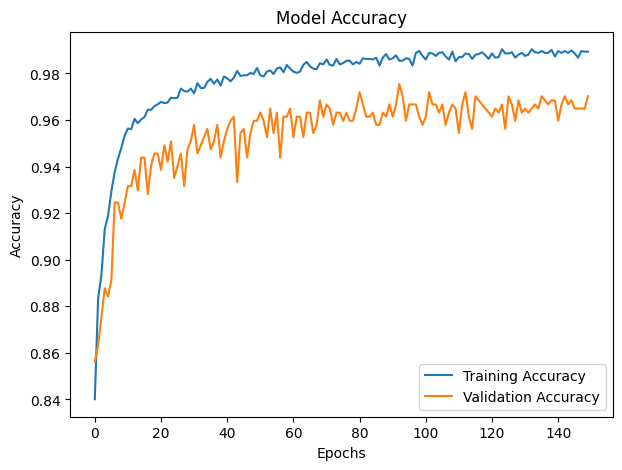

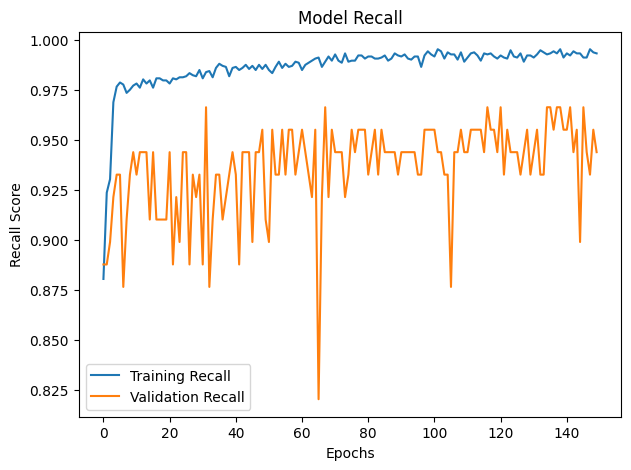

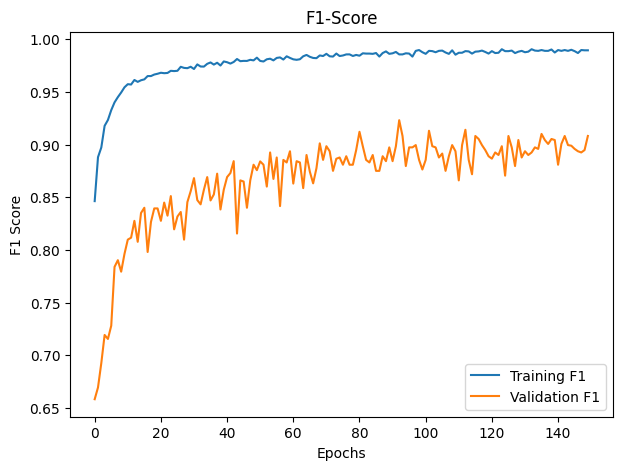

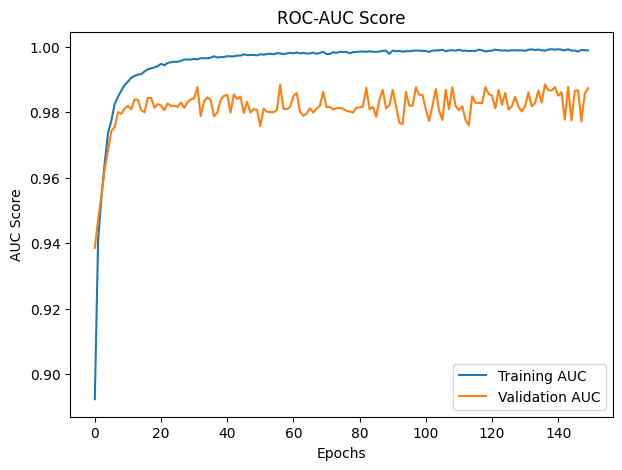

In [ ]:
44. # ANN Classification with Training and Validation Plots

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from imblearn.over_sampling import SMOTE

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

import numpy as np
import matplotlib.pyplot as plt


# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=52,
    stratify=y
)


# SMOTE

smote = SMOTE(random_state=50)

X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)


# Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ANN model

ann = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])


# Compile ANN

ann.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        'Precision',
        'Recall',
        'AUC'
    ]
)


# Train ANN

history = ann.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)


# Test prediction

y_prob = ann.predict(
    X_test,
    verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)


# Final metrics

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))


# Calculate F1 Score for Training and Validation

train_precision = np.array(history.history['Precision'])
train_recall = np.array(history.history['Recall'])

val_precision = np.array(history.history['val_Precision'])
val_recall = np.array(history.history['val_Recall'])

train_f1 = (
    2 * train_precision * train_recall
    / (train_precision + train_recall)
)

val_f1 = (
    2 * val_precision * val_recall
    / (val_precision + val_recall)
)

# Accuracy plot

plt.figure(figsize=(7, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

# Recall plot

plt.figure(figsize=(7, 5))

plt.plot(
    history.history['Recall'],
    label='Training Recall'
)

plt.plot(
    history.history['val_Recall'],
    label='Validation Recall'
)

plt.title('Model Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall Score')
plt.legend()

plt.show()


# F1-Score plot

plt.figure(figsize=(7, 5))

plt.plot(
    train_f1,
    label='Training F1'
)

plt.plot(
    val_f1,
    label='Validation F1'
)

plt.title('F1-Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()

plt.show()


# ROC-AUC plot

plt.figure(figsize=(7, 5))

plt.plot(
    history.history['AUC'],
    label='Training AUC'
)

plt.plot(
    history.history['val_AUC'],
    label='Validation AUC'
)

plt.title('ROC-AUC Score')
plt.xlabel('Epochs')
plt.ylabel('AUC Score')
plt.legend()

plt.show()

In [ ]:
45.# Grid Search for Logistic Regression Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

lg_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    lg = LogisticRegression(
        solver='liblinear',
        random_state=42
    )

    param_grid = {
        'C': [0.01, 0.1, 1],
        'penalty': ['l1', 'l2'],
        'class_weight': [None, 'balanced']
    }

    grid_search = GridSearchCV(
        lg,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_lg = grid_search.best_estimator_

    y_pred = best_lg.predict(X_test)
    y_prob = best_lg.predict_proba(X_test)[:, 1]

    lg_accuracy = accuracy_score(y_test, y_pred)
    lg_precision = precision_score(y_test, y_pred)
    lg_recall = recall_score(y_test, y_pred)
    lg_f1 = f1_score(y_test, y_pred)
    lg_roc_auc = roc_auc_score(y_test, y_prob)

    lg_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        lg_accuracy,
        lg_precision,
        lg_recall,
        lg_f1,
        lg_roc_auc
    ])

lg_results = pd.DataFrame(
    lg_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(lg_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.903509,0.895614,0.817204,0.426966,0.560886,0.929731
1,65:35,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.900103,0.892786,0.802469,0.416667,0.548523,0.928844
2,70:30,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.899749,0.894737,0.805556,0.432836,0.563107,0.928639
3,75:25,"{'C': 1, 'class_weight': None, 'penalty': 'l1'}",0.897520,0.892006,0.753623,0.464286,0.574586,0.929173
4,80:20,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.900439,0.889474,0.770833,0.415730,0.540146,0.913336


In [ ]:
46.# Grid Search for KNN Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

knn_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    knn = KNeighborsClassifier()

    param_grid = {
        'n_neighbors': [5, 10, 15],
        'p': [1, 2, 3, 4]
    }

    grid_search = GridSearchCV(
        knn,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_knn = grid_search.best_estimator_

    y_pred = best_knn.predict(X_test)
    y_prob = best_knn.predict_proba(X_test)[:, 1]

    knn_accuracy = accuracy_score(y_test, y_pred)
    knn_precision = precision_score(y_test, y_pred)
    knn_recall = recall_score(y_test, y_pred)
    knn_f1 = f1_score(y_test, y_pred)
    knn_roc_auc = roc_auc_score(y_test, y_prob)

    knn_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        knn_accuracy,
        knn_precision,
        knn_recall,
        knn_f1,
        knn_roc_auc
    ])

knn_results = pd.DataFrame(
    knn_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(knn_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'n_neighbors': 5, 'p': 1}",0.867251,0.866667,0.618182,0.382022,0.472222,0.824184
1,65:35,"{'n_neighbors': 5, 'p': 1}",0.863395,0.866733,0.621053,0.378205,0.470120,0.829237
2,70:30,"{'n_neighbors': 5, 'p': 1}",0.867168,0.860819,0.590361,0.365672,0.451613,0.826516
3,75:25,"{'n_neighbors': 5, 'p': 1}",0.860540,0.866760,0.613333,0.410714,0.491979,0.850250
4,80:20,"{'n_neighbors': 5, 'p': 1}",0.867544,0.871930,0.625000,0.449438,0.522876,0.846679


In [ ]:
47. # Grid Search for Decision Tree Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

dt_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    dt = DecisionTreeClassifier(random_state=42)

    param_grid = {
        'max_depth': [5, 10, 20],
        'min_samples_leaf': [1, 2, 5, 10]
    }

    grid_search = GridSearchCV(
        dt,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_dt = grid_search.best_estimator_

    y_pred = best_dt.predict(X_test)
    y_prob = best_dt.predict_proba(X_test)[:, 1]

    dt_accuracy = accuracy_score(y_test, y_pred)
    dt_precision = precision_score(y_test, y_pred)
    dt_recall = recall_score(y_test, y_pred)
    dt_f1 = f1_score(y_test, y_pred)
    dt_roc_auc = roc_auc_score(y_test, y_prob)

    dt_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1,
        dt_roc_auc
    ])

dt_results = pd.DataFrame(
    dt_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(dt_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'max_depth': 10, 'min_samples_leaf': 5}",0.943275,0.935965,0.818182,0.758427,0.787172,0.921804
1,65:35,"{'max_depth': 10, 'min_samples_leaf': 1}",0.944387,0.930862,0.853659,0.673077,0.752688,0.894908
2,70:30,"{'max_depth': 10, 'min_samples_leaf': 5}",0.941353,0.941520,0.828125,0.791045,0.809160,0.934176
3,75:25,"{'max_depth': 10, 'min_samples_leaf': 1}",0.942442,0.949509,0.904255,0.758929,0.825243,0.921871
4,80:20,"{'max_depth': 20, 'min_samples_leaf': 5}",0.942544,0.933333,0.814815,0.741573,0.776471,0.924338


In [ ]:
48. # Grid Search for Random Forest Classification

rf_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    rf_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )

    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 20, 30, None],
        'min_samples_leaf': [1, 2, 5, 10]
    }

    grid_search = GridSearchCV(
        rf_model,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_rf = grid_search.best_estimator_

    y_pred_rf = best_rf.predict(X_test)
    y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

    rf_accuracy = accuracy_score(y_test, y_pred_rf)
    rf_precision = precision_score(y_test, y_pred_rf)
    rf_recall = recall_score(y_test, y_pred_rf)
    rf_f1 = f1_score(y_test, y_pred_rf)
    rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

    rf_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ])

rf_results = pd.DataFrame(
    rf_results,
    columns=[
        "Split",
        "Best Parameters",
        "Best CV Accuracy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
)

display(rf_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.948538,0.949123,0.922535,0.735955,0.818750,0.978246
1,65:35,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.950324,0.946894,0.918699,0.724359,0.810036,0.977587
2,70:30,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.951378,0.948538,0.901786,0.753731,0.821138,0.976634
3,75:25,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.952730,0.950912,0.923077,0.750000,0.827586,0.979216
4,80:20,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.954825,0.950877,0.942029,0.730337,0.822785,0.972225


In [ ]:
49. # Grid Search for AdaBoost Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

ada_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    ada = AdaBoostClassifier(random_state=42)

    param_grid = {
        'n_estimators': [50, 100, 200],
        'learning_rate': [0.01, 0.05, 0.1, 0.5]
    }

    grid_search = GridSearchCV(
        ada,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_ada = grid_search.best_estimator_

    y_pred = best_ada.predict(X_test)
    y_prob = best_ada.predict_proba(X_test)[:, 1]

    ada_accuracy = accuracy_score(y_test, y_pred)
    ada_precision = precision_score(y_test, y_pred)
    ada_recall = recall_score(y_test, y_pred)
    ada_f1 = f1_score(y_test, y_pred)
    ada_roc_auc = roc_auc_score(y_test, y_prob)

    ada_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        ada_accuracy,
        ada_precision,
        ada_recall,
        ada_f1,
        ada_roc_auc
    ])

ada_results = pd.DataFrame(
    ada_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(ada_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'learning_rate': 0.5, 'n_estimators': 200}",0.909357,0.897368,0.906667,0.382022,0.537549,0.954534
1,65:35,"{'learning_rate': 0.5, 'n_estimators': 200}",0.908736,0.895792,0.882353,0.384615,0.535714,0.952384
2,70:30,"{'learning_rate': 0.5, 'n_estimators': 100}",0.906767,0.894737,0.892857,0.373134,0.526316,0.945815
3,75:25,"{'learning_rate': 0.5, 'n_estimators': 100}",0.903130,0.899018,0.916667,0.392857,0.550000,0.947818
4,80:20,"{'learning_rate': 0.5, 'n_estimators': 200}",0.907456,0.892982,0.888889,0.359551,0.512000,0.944766


In [ ]:
50. # Grid Search for Gradient Boosting Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

gb_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    gb = GradientBoostingClassifier(random_state=42)

    param_grid = {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.2]
    }

    grid_search = GridSearchCV(
        gb,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_gb = grid_search.best_estimator_

    y_pred = best_gb.predict(X_test)
    y_prob = best_gb.predict_proba(X_test)[:, 1]

    gb_accuracy = accuracy_score(y_test, y_pred)
    gb_precision = precision_score(y_test, y_pred)
    gb_recall = recall_score(y_test, y_pred)
    gb_f1 = f1_score(y_test, y_pred)
    gb_roc_auc = roc_auc_score(y_test, y_prob)

    gb_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        gb_accuracy,
        gb_precision,
        gb_recall,
        gb_f1,
        gb_roc_auc
    ])

gb_results = pd.DataFrame(
    gb_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(gb_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'learning_rate': 0.2, 'n_estimators': 300}",0.949708,0.956140,0.938356,0.769663,0.845679,0.980574
1,65:35,"{'learning_rate': 0.2, 'n_estimators': 300}",0.946540,0.954910,0.930233,0.769231,0.842105,0.977263
2,70:30,"{'learning_rate': 0.2, 'n_estimators': 200}",0.948371,0.949708,0.909910,0.753731,0.824490,0.974843
3,75:25,"{'learning_rate': 0.2, 'n_estimators': 300}",0.946181,0.962132,0.938144,0.812500,0.870813,0.975673
4,80:20,"{'learning_rate': 0.2, 'n_estimators': 300}",0.950877,0.954386,0.920000,0.775281,0.841463,0.975846


In [ ]:
51. # Grid Search for XGBoost Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

xgb_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    xgb = XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )

    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 4, 6, 8]
    }

    grid_search = GridSearchCV(
        xgb,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_xgb = grid_search.best_estimator_

    y_pred = best_xgb.predict(X_test)
    y_prob = best_xgb.predict_proba(X_test)[:, 1]

    xgb_accuracy = accuracy_score(y_test, y_pred)
    xgb_precision = precision_score(y_test, y_pred)
    xgb_recall = recall_score(y_test, y_pred)
    xgb_f1 = f1_score(y_test, y_pred)
    xgb_roc_auc = roc_auc_score(y_test, y_prob)

    xgb_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        xgb_accuracy,
        xgb_precision,
        xgb_recall,
        xgb_f1,
        xgb_roc_auc
    ])

xgb_results = pd.DataFrame(
    xgb_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(xgb_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'max_depth': 6, 'n_estimators': 100}",0.955556,0.955263,0.909677,0.792135,0.846847,0.982328
1,65:35,"{'max_depth': 4, 'n_estimators': 100}",0.950859,0.955912,0.937500,0.769231,0.845070,0.984085
2,70:30,"{'max_depth': 3, 'n_estimators': 100}",0.950877,0.956725,0.921739,0.791045,0.851406,0.983724
3,75:25,"{'max_depth': 4, 'n_estimators': 200}",0.952269,0.953717,0.924731,0.767857,0.839024,0.981244
4,80:20,"{'max_depth': 8, 'n_estimators': 300}",0.958333,0.961404,0.946667,0.797753,0.865854,0.974398


In [ ]:
52. # Grid Search for SVC Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

svc_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    svc = SVC(
        probability=True,
        random_state=42
    )

    param_grid = {
        'C': [0.1, 1, 10],
        'gamma': ['scale', 'auto', 0.01, 0.1]
    }

    grid_search = GridSearchCV(
        svc,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_svc = grid_search.best_estimator_

    y_pred = best_svc.predict(X_test)
    y_prob = best_svc.predict_proba(X_test)[:, 1]

    svc_accuracy = accuracy_score(y_test, y_pred)
    svc_precision = precision_score(y_test, y_pred)
    svc_recall = recall_score(y_test, y_pred)
    svc_f1 = f1_score(y_test, y_pred)
    svc_roc_auc = roc_auc_score(y_test, y_prob)

    svc_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        svc_accuracy,
        svc_precision,
        svc_recall,
        svc_f1,
        svc_roc_auc
    ])

svc_results = pd.DataFrame(
    svc_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(svc_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'C': 1, 'gamma': 0.01}",0.864327,0.855263,0.651163,0.157303,0.253394,0.702203
1,65:35,"{'C': 1, 'gamma': 0.01}",0.865008,0.853707,0.647059,0.141026,0.231579,0.720313
2,70:30,"{'C': 10, 'gamma': 0.01}",0.864662,0.852632,0.653846,0.126866,0.212500,0.714560
3,75:25,"{'C': 1, 'gamma': 0.01}",0.864756,0.856942,0.692308,0.160714,0.260870,0.737246
4,80:20,"{'C': 1, 'gamma': 0.01}",0.862719,0.854386,0.666667,0.134831,0.224299,0.735780


In [ ]:
53. # Grid Search for Naive Bayes Classification - 5 Splits

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

nb_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    nb = GaussianNB()

    param_grid = {
        'var_smoothing': [1e-9, 1e-5, 1e-1],
        'priors': [
            [0.2, 0.8],
            [0.3, 0.7],
            [0.4, 0.6],
            [0.5, 0.5]
        ]
    }

    grid_search = GridSearchCV(
        nb,
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_nb = grid_search.best_estimator_

    y_pred = best_nb.predict(X_test)
    y_prob = best_nb.predict_proba(X_test)[:, 1]

    nb_accuracy = accuracy_score(y_test, y_pred)
    nb_precision = precision_score(y_test, y_pred)
    nb_recall = recall_score(y_test, y_pred)
    nb_f1 = f1_score(y_test, y_pred)
    nb_roc_auc = roc_auc_score(y_test, y_prob)

    nb_results.append([
        split_name,
        grid_search.best_params_,
        grid_search.best_score_,
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1,
        nb_roc_auc
    ])

nb_results = pd.DataFrame(
    nb_results,
    columns=[
        "Split", "Best Parameters", "Best CV Accuracy",
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
    ]
)

display(nb_results)

,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,60:40,"{'priors': [0.5, 0.5], 'var_smoothing': 1e-09}",0.674269,0.685965,0.324219,0.932584,0.481159,0.907955
1,65:35,"{'priors': [0.5, 0.5], 'var_smoothing': 1e-09}",0.675494,0.684369,0.322940,0.929487,0.479339,0.904794
2,70:30,"{'priors': [0.5, 0.5], 'var_smoothing': 1e-09}",0.679198,0.691228,0.328042,0.925373,0.484375,0.903942
3,75:25,"{'priors': [0.5, 0.5], 'var_smoothing': 1e-09}",0.678523,0.695652,0.330097,0.910714,0.484561,0.900575
4,80:20,"{'priors': [0.5, 0.5], 'var_smoothing': 1e-09}",0.681140,0.685965,0.318548,0.887640,0.468843,0.882198


In [ ]:
54. # All Grid Search Classification Results

all_grid_results = pd.concat([
    lg_results.assign(Model="Logistic Regression"),
    knn_results.assign(Model="KNN"),
    dt_results.assign(Model="Decision Tree"),
    rf_results.assign(Model="Random Forest"),
    ada_results.assign(Model="AdaBoost"),
    gb_results.assign(Model="Gradient Boosting"),
    xgb_results.assign(Model="XGBoost"),
    svc_results.assign(Model="SVC"),
    nb_results.assign(Model="Naive Bayes")
], ignore_index=True)

all_grid_results = all_grid_results[
    [
        "Model",
        "Split",
        "Best Parameters",
        "Best CV Accuracy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

display(all_grid_results)

,Model,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,60:40,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.903509,0.895614,0.817204,0.426966,0.560886,0.929731
1,Logistic Regression,65:35,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.900103,0.892786,0.802469,0.416667,0.548523,0.928844
2,Logistic Regression,70:30,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.899749,0.894737,0.805556,0.432836,0.563107,0.928639
3,Logistic Regression,75:25,"{'C': 1, 'class_weight': None, 'penalty': 'l1'}",0.897520,0.892006,0.753623,0.464286,0.574586,0.929173
4,Logistic Regression,80:20,"{'C': 0.1, 'class_weight': None, 'penalty': 'l1'}",0.900439,0.889474,0.770833,0.415730,0.540146,0.913336
5,KNN,60:40,"{'n_neighbors': 5, 'p': 1}",0.867251,0.866667,0.618182,0.382022,0.472222,0.824184
6,KNN,65:35,"{'n_neighbors': 5, 'p': 1}",0.863395,0.866733,0.621053,0.378205,0.470120,0.829237
7,KNN,70:30,"{'n_neighbors': 5, 'p': 1}",0.867168,0.860819,0.590361,0.365672,0.451613,0.826516
8,KNN,75:25,"{'n_neighbors': 5, 'p': 1}",0.860540,0.866760,0.613333,0.410714,0.491979,0.850250
9,KNN,80:20,"{'n_neighbors': 5, 'p': 1}",0.867544,0.871930,0.625000,0.449438,0.522876,0.846679


In [ ]:
55. # Highest Accuracy

highest_accuracy = all_grid_results.loc[
    [all_grid_results["Accuracy"].idxmax()]
]

display(highest_accuracy)

,Model,Split,Best Parameters,Best CV Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
28,Gradient Boosting,75:25,"{'learning_rate': 0.2, 'n_estimators': 300}",0.946181,0.962132,0.938144,0.8125,0.870813,0.975673
